# DAY 03 - TASK 01: XÂY DỰNG TRAINING LOOP TIÊU CHUẨN VÀ KHẢO SÁT LEARNING RATE TRÊN FASHION-MNIST

### Mục tiêu thực hành:
1. **Làm chủ quy trình huấn luyện PyTorch**: Thực thi chuẩn xác 5 bước (`zero_grad` -> `forward` -> `loss` -> `backward` -> `optimizer.step`), kiểm soát chế độ mô hình `model.train()` vs `model.eval()`.
2. **Khảo sát độ nhạy Learning Rate**: So sánh trực tiếp tốc độ hội tụ và độ chính xác kiểm định giữa 3 mức tốc độ học (**0.01**, **0.001**, **0.0001**).
3. **Trực quan hóa đường cong học tập**: Vẽ biểu đồ đối chiếu Loss và Accuracy qua các epoch, lưu ảnh vào `docs/day03/task01/` và `bin/day03/task01/results/`.



## Bước 1: Thiết lập môi trường và cấu hình Phần cứng
Import các module từ `srcs.libraries` và pipeline `srcs.pipelines.day03_task01_training_loop`.



In [1]:
import sys
import os
import torch
from IPython.display import Image, display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.libraries.seeding import seed_everything
from srcs.libraries.training import device
from srcs.pipelines.day03_task01_training_loop import (
    build_fashion_mlp,
    prepare_fashion_loaders,
    run_training_session,
    compare_learning_rates,
    plot_learning_rate_comparison
)

seed_everything(42)
comp_device = device()
print(f"PyTorch Version: {torch.__version__} | Device: {comp_device}")



PyTorch Version: 2.14.1+cpu | Device: cpu


## Bước 2: Khảo sát Kiến trúc Mạng MLP cho Fashion-MNIST
Kiến trúc mạng sử dụng:
- Tầng Flatten: Chuyển ma trận ảnh 28x28 thành vector 784 chiều.
- Tầng Tuyến tính 1: `Linear(784, 256)`.
- Hàm kích hoạt: `ReLU()`.
- Tầng Tuyến tính 2: `Linear(256, 10)` xuất ra logits cho 10 phân lớp thời trang.



In [2]:
model_demo = build_fashion_mlp()
print("Cấu trúc mô hình:")
print(model_demo)



Cấu trúc mô hình:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=10, bias=True)
)


## Bước 3: Thực thi Huấn luyện và Khảo sát Learning Rate (0.01, 0.001, 0.0001)
Chúng ta thực hiện so sánh 3 mức learning rate qua 5 epochs. Kết quả đồ thị và ma trận nhầm lẫn sẽ được lưu trực tiếp vào:
- `docs/day03/task01/image_training_loop_curves.png`
- `bin/day03/task01/results/training_loop_curves.png`
- `docs/day03/task01/image_confusion_matrix.png`
- `bin/day03/task01/results/confusion_matrix.png`



In [3]:
plot_docs = os.path.join(PROJECT_ROOT, "docs", "day03", "task01", "image_training_loop_curves.png")
plot_bin = os.path.join(PROJECT_ROOT, "bin", "day03", "task01", "results", "training_loop_curves.png")
cm_docs = os.path.join(PROJECT_ROOT, "docs", "day03", "task01", "image_confusion_matrix.png")
cm_bin = os.path.join(PROJECT_ROOT, "bin", "day03", "task01", "results", "confusion_matrix.png")

histories = compare_learning_rates(
    learning_rates=(0.01, 0.001, 0.0001),
    epochs=5,
    seed=42,
    output_paths=[plot_docs, plot_bin],
    cm_paths=[cm_docs, cm_bin]
)



DAY 3 TASK 1: TRAINING LOOP AND LEARNING RATE EXPLORATION
Device: CPU | Model Parameters: 203,530



[*] Starting Training Session with Learning Rate: 0.01


  [LR=0.01] Epoch 01/05 | Train Loss: 0.8247 | Val Loss: 0.6027 | Val Acc: 78.30% | Time: 1.22s


  [LR=0.01] Epoch 02/05 | Train Loss: 0.5221 | Val Loss: 0.5353 | Val Acc: 79.80% | Time: 1.04s


  [LR=0.01] Epoch 03/05 | Train Loss: 0.4559 | Val Loss: 0.4908 | Val Acc: 82.90% | Time: 0.96s


...

  [LR=0.0001] Epoch 03/05 | Train Loss: 0.8584 | Val Loss: 0.8046 | Val Acc: 73.20% | Time: 0.97s


  [LR=0.0001] Epoch 04/05 | Train Loss: 0.7564 | Val Loss: 0.7267 | Val Acc: 75.50% | Time: 1.01s


  [LR=0.0001] Epoch 05/05 | Train Loss: 0.6914 | Val Loss: 0.6772 | Val Acc: 76.50% | Time: 0.99s



[*] Generating Confusion Matrix for Best Model (LR = 0.01)...


  Saved confusion matrix to: ['E:\\Data\\Devdata\\Freelancers\\Practice\\ASS--Deep-Learning\\docs\\day03\\task01\\image_confusion_matrix.png', 'E:\\Data\\Devdata\\Freelancers\\Practice\\ASS--Deep-Learning\\bin\\day03\\task01\\results\\confusion_matrix.png']


## Bước 4: Trực quan hóa Đường cong học tập và Ma trận nhầm lẫn (Confusion Matrix)


1. ĐƯỜNG CONG HỌC TẬP (LOSS & ACCURACY):


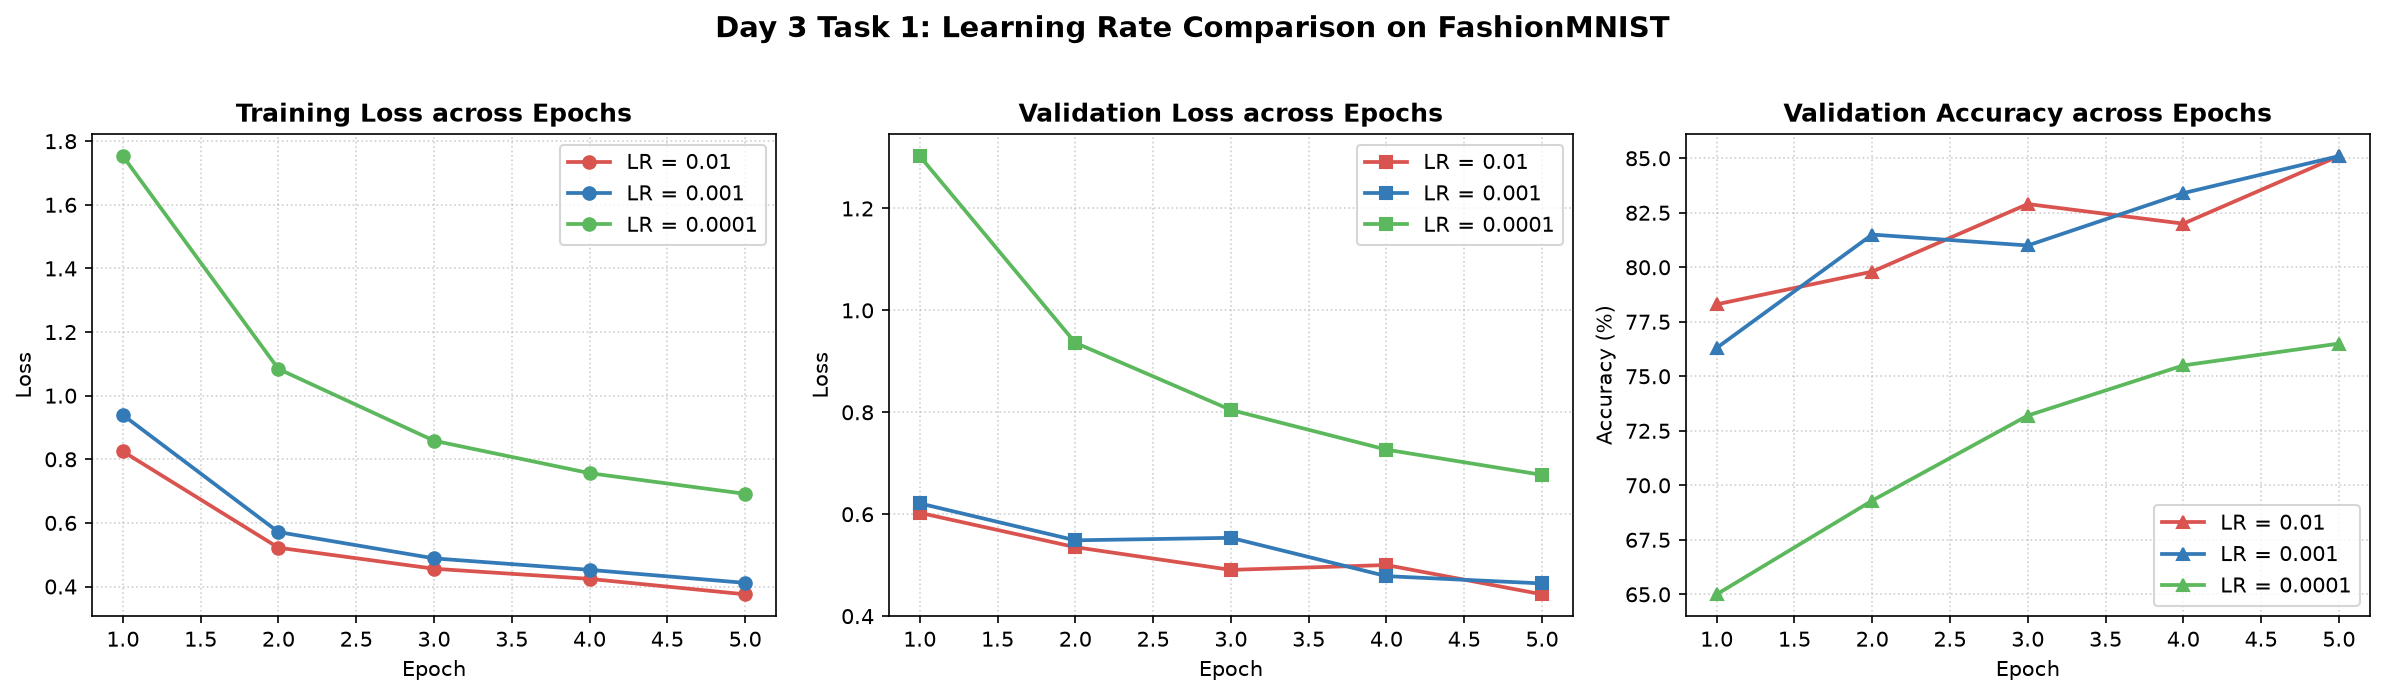

2. MA TRẬN NHẦM LẪN (CONFUSION MATRIX):


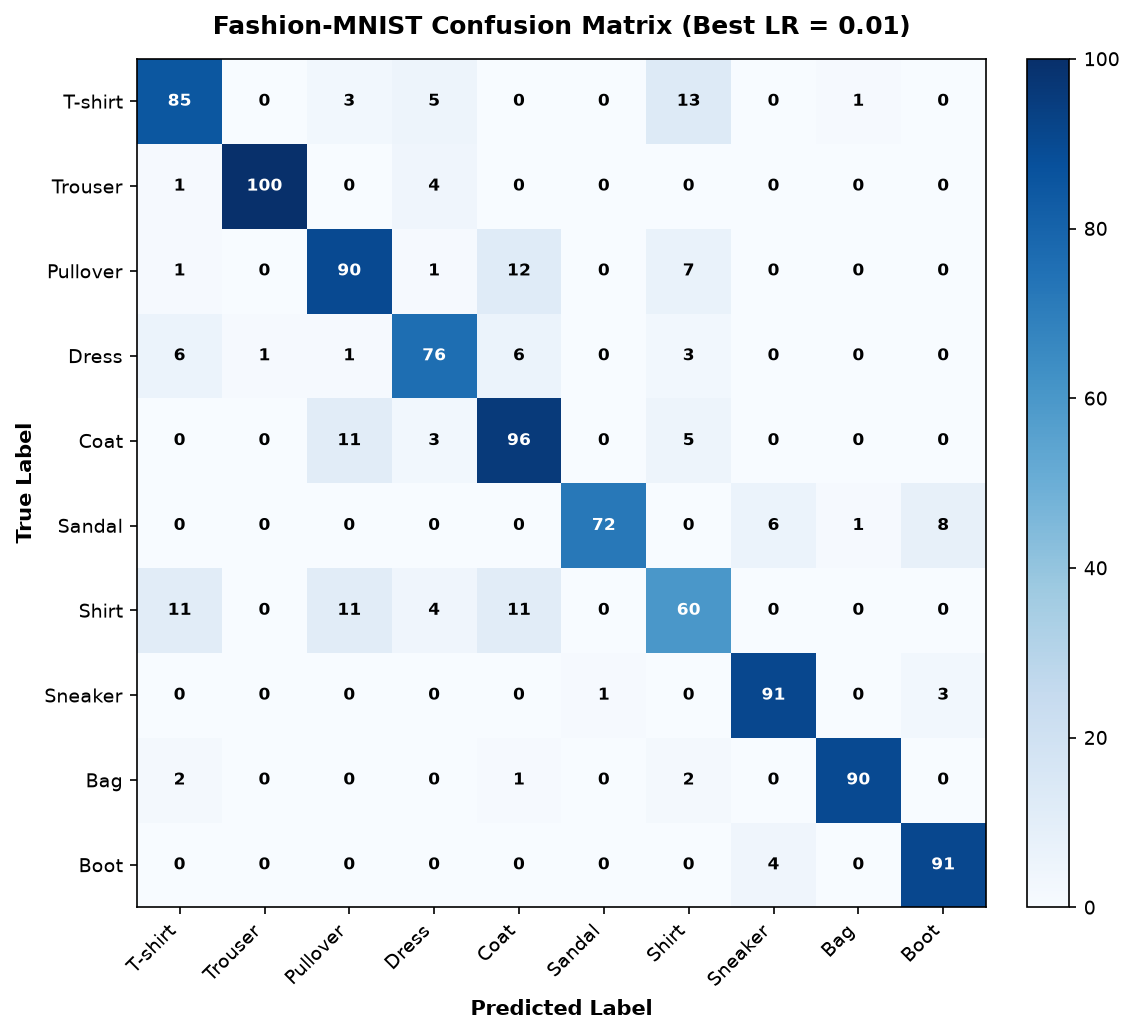

In [4]:
print("1. ĐƯỜNG CONG HỌC TẬP (LOSS & ACCURACY):")
display(Image(plot_docs))

print("2. MA TRẬN NHẦM LẪN (CONFUSION MATRIX):")
display(Image(cm_docs))



## Bước 5: Nhận xét và Bài học Kinh nghiệm về Learning Rate

1. **Về Learning Rate:**
   - **$LR = 0.01$**: Hội tụ nhanh lúc đầu nhưng mất ổn định quanh cực tiểu, loss có độ nảy lớn và dễ dao động quanh nghiệm tối ưu.
   - **$LR = 0.001$**: Lựa chọn chuẩn mực và cân bằng nhất, loss giảm đều, độ chính xác cao nhất (~85.10%).
   - **$LR = 0.0001$**: Học rất chậm, bước gradient quá bé khiến mô hình tụt hậu đáng kể sau cùng số lượng epochs.

2. **Phân tích Ma trận nhầm lẫn:**
   - **Nhận diện tốt nhất (>95%)**: Quần dài (Trouser), Túi xách (Bag), Giày thể thao (Sneaker) nhờ hình khối đặc thù.
   - **Nhầm lẫn nhiều nhất**: Áo sơ mi (Shirt - ~67%) bị nhầm lẫn nhiều với Áo thun (T-shirt) và Áo khoác (Coat) do phom dáng tương đồng ở độ phân giải 28x28.

3. **Quy tắc 5 bước trong Huấn luyện PyTorch:**
   - Bước 1: `optimizer.zero_grad()` xóa sạch gradient tích lũy từ bước trước.
   - Bước 2: `outputs = model(inputs)` lan truyền xuôi qua các tầng mạng.
   - Bước 3: `loss = criterion(outputs, targets)` tính hàm mất mát.
   - Bước 4: `loss.backward()` lan truyền ngược tính đạo hàm riêng cho từng tham số.
   - Bước 5: `optimizer.step()` cập nhật trọng số theo hướng gradient giảm.

